# --------------------------: Image Classification (CIFAR 10) :----------------------------

## 1. Import Libraries : 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

print("PyTorch Version : ", torch.__version__)
print("Torchvision Version : ", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device : ", device)

PyTorch Version :  2.10.0+cu126
Torchvision Version :  0.25.0+cu126
Device :  cuda


## 2. Load the Dataset : 

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset = torchvision.datasets.CIFAR10(root = './data', train = True, download = True, transform = transform)
test_dataset = torchvision.datasets.CIFAR10(root = './data', train = False, download = True, transform = transform)

print("Training samples : ", len(train_dataset))
print("Testing samples : ", len(test_dataset))
print("Image shape : ", train_dataset[0][0].shape)

Training samples :  50000
Testing samples :  10000
Image shape :  torch.Size([3, 32, 32])


## 3. Create DataLoaders : 

In [3]:
train_loader = torch.utils.data.DataLoader(dataset = train_dataset, batch_size = 64, shuffle = True, num_workers = 0)
test_loader = torch.utils.data.DataLoader(dataset = test_dataset, batch_size = 64, shuffle = False, num_workers = 0)

print("Training batches : ", len(train_loader))
print("Testing batches : ", len(test_loader))

Training batches :  782
Testing batches :  157


## 4. Display Sample Images : 

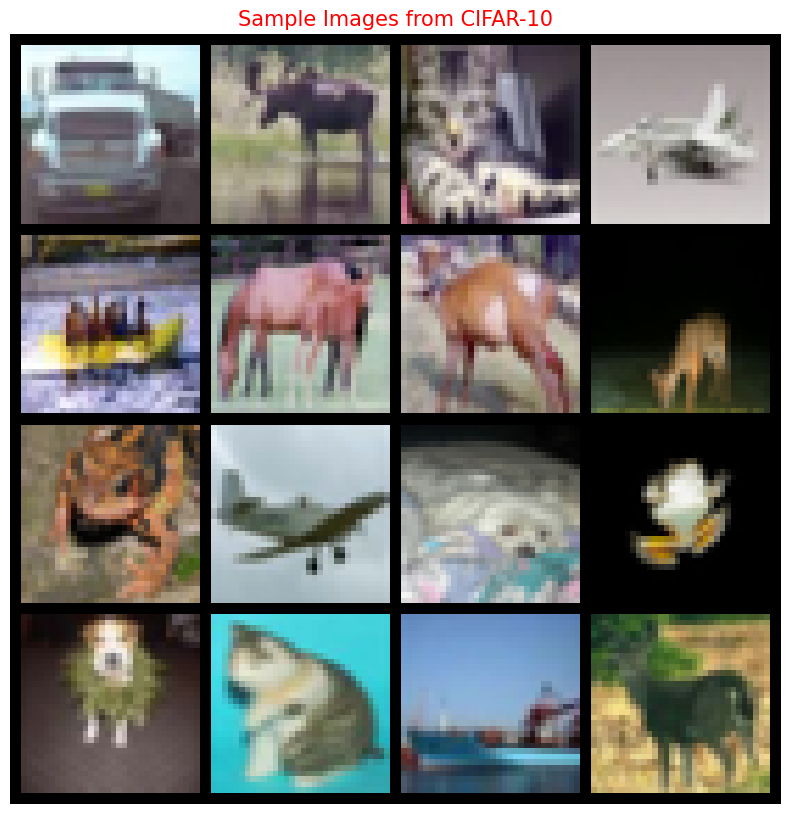

Image labels : 
truck | deer | cat | airplane | ship | horse | deer | deer | frog | airplane | dog | frog | dog | cat | ship | deer | 

In [4]:
classes = ('airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

images, labels = next(iter(train_loader))
images = images[ : 16]
labels = labels[ : 16]
images = images / 2 + 0.5

grid = torchvision.utils.make_grid(images, nrow = 4)

plt.figure(figsize = (20, 10))
plt.imshow(np.transpose(grid.numpy(), (1, 2, 0)))
plt.axis('off')
plt.title("Sample Images from CIFAR-10", fontsize = 15, color = "red")
plt.show()

print("Image labels : ")

for i in range(len(labels)) :
    print(classes[labels[i].item()], end=" | ")

## 5. Define CNN Model : 

In [5]:
class CNN(nn.Module) :
    def __init__(self) :
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(in_channels = 3, out_channels = 32, kernel_size = 3, padding = 1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size = 2, stride = 2)

        self.conv2 = nn.Conv2d(in_channels = 32, out_channels = 64, kernel_size = 3, padding = 1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size = 2, stride = 2)

        self.conv3 = nn.Conv2d(in_channels = 64, out_channels = 128, kernel_size = 3, padding = 1)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(kernel_size = 2, stride = 2)

        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.relu4 = nn.ReLU()
        self.fc2 = nn.Linear(256, 10)

    
    def forward(self, x) :
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.pool3(self.relu3(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.relu4(self.fc1(x))
        x = self.fc2(x)

        return x

## 6. Initialize the Model : 

In [6]:
model = CNN().to(device)

print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (relu4): ReLU()
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


In [7]:
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total trainable parameters : ", total_params)

Total trainable parameters :  620362


## 7. Loss Function and Optimizer : 

In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.001)

print(criterion)
print(optimizer)

CrossEntropyLoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 8. Train the Model : 

In [9]:
num_epochs = 10

train_losses = []
train_accuracies = []

for epoch in range(num_epochs) :
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader :
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(f"Epoch [{epoch + 1}/{num_epochs}] "f"Loss : {epoch_loss:.4f} "f"Accuracy : {epoch_accuracy:.2f}%")

Epoch [1/10] Loss : 1.3557 Accuracy : 51.00%
Epoch [2/10] Loss : 0.9294 Accuracy : 67.12%
Epoch [3/10] Loss : 0.7521 Accuracy : 73.63%
Epoch [4/10] Loss : 0.6358 Accuracy : 77.67%
Epoch [5/10] Loss : 0.5311 Accuracy : 81.44%
Epoch [6/10] Loss : 0.4405 Accuracy : 84.47%
Epoch [7/10] Loss : 0.3557 Accuracy : 87.46%
Epoch [8/10] Loss : 0.2854 Accuracy : 89.90%
Epoch [9/10] Loss : 0.2193 Accuracy : 92.28%
Epoch [10/10] Loss : 0.1726 Accuracy : 93.88%


## 9. Evaluate the Model : 

In [27]:
model.eval()

correct = 0
total = 0
test_loss = 0.0

with torch.no_grad() :
    for images, labels in test_loader :
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        test_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()


test_accuracy = 100 * correct / total
average_test_loss = test_loss / len(test_loader)

print("Original CNN Evaluation Results")
print("-" * 35)
print(f"Test Accuracy : {test_accuracy:.2f}%")
print(f"Test Loss :  {average_test_loss:.4f}")

Original CNN Evaluation Results
-----------------------------------
Test Accuracy : 75.22%
Test Loss :  1.0405


## 10. Plot Training Loss and Accuracy :

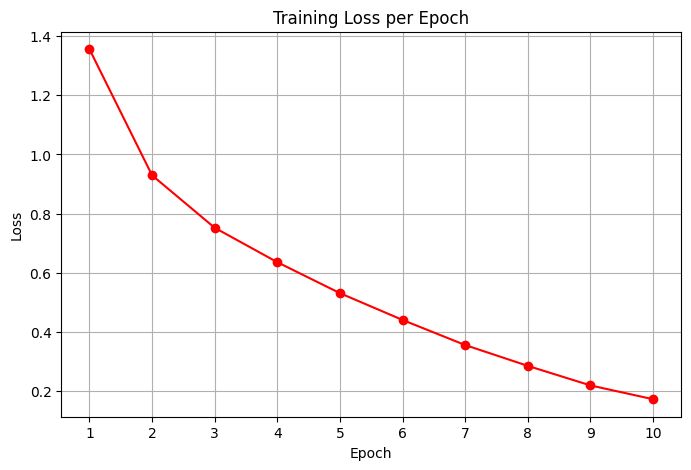

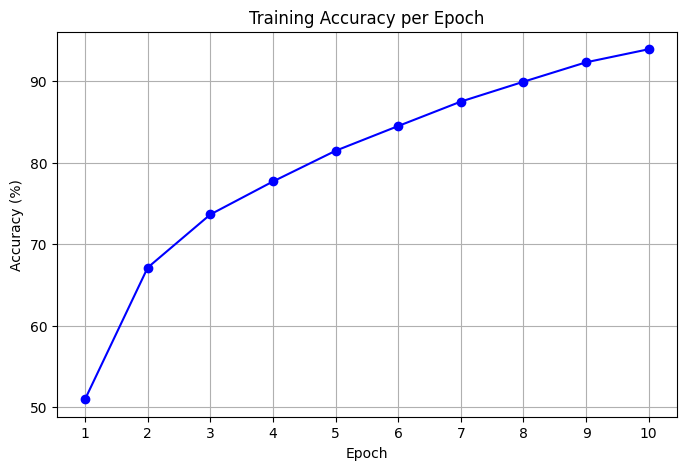

In [11]:
plt.figure(figsize = (8, 5))
plt.plot(range(1, num_epochs + 1), train_losses, marker = 'o', color = "red")
plt.title("Training Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(1, num_epochs + 1))
plt.grid(True)
plt.show()


plt.figure(figsize = (8, 5))
plt.plot(range(1, num_epochs + 1), train_accuracies, marker = 'o', color = "blue")
plt.title("Training Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(range(1, num_epochs + 1))
plt.grid(True)
plt.show()

## 11. Calculate Accuracy for Each Class :

In [12]:
class_correct = [0] * 10
class_total = [0] * 10

model.eval()

with torch.no_grad() :
    for images, labels in test_loader :
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        for i in range(labels.size(0)) :
            label = labels[i].item()
            class_total[label] += 1
            class_correct[label] += (predicted[i].item() == label)


for i in range(10) :
    accuracy = 100 * class_correct[i] / class_total[i]
    print(f"{classes[i]} : {accuracy:.2f}%")

airplane : 77.60%
automobile : 90.10%
bird : 64.50%
cat : 45.00%
deer : 74.70%
dog : 73.90%
frog : 79.00%
horse : 82.90%
ship : 87.00%
truck : 77.50%


## 12. Save Trained Model : 

In [13]:
torch.save(model.state_dict(), "cifar10_cnn.pth")

print("Model saved successfully!")

Model saved successfully!


## 13. Confusion Matrix : 

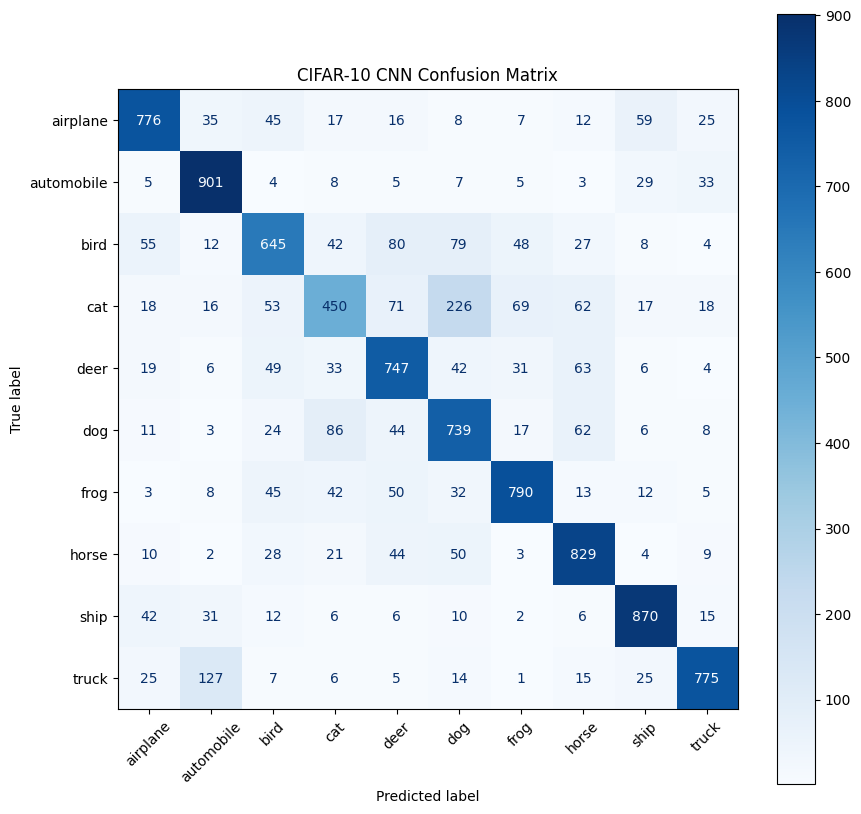

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = []
y_pred = []

model.eval()

with torch.no_grad() :
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())


cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = classes)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax = ax, cmap = 'Blues', xticks_rotation = 45, values_format = 'd')
plt.title("CIFAR-10 CNN Confusion Matrix")
plt.show()

## 14. Display Predictions for Individual Images :

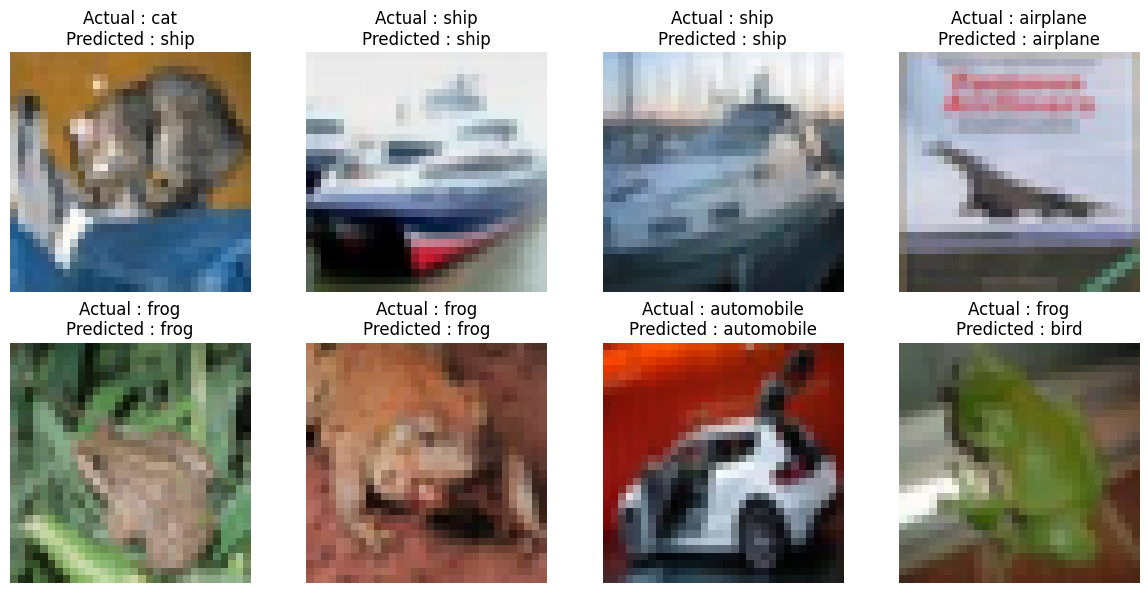

In [15]:
images, labels = next(iter(test_loader))
images_device = images.to(device)

model.eval()

with torch.no_grad() :
    outputs = model(images_device)
    _, predictions = torch.max(outputs, 1)


fig, axes = plt.subplots(2, 4, figsize = (12, 6))

for i, ax in enumerate(axes.flat) :
    img = images[i] / 2 + 0.5
    img = np.transpose(img.numpy(), (1, 2, 0))
    actual_label = classes[labels[i].item()]
    predicted_label = classes[predictions[i].item()]
    ax.imshow(img)
    ax.set_title(f"Actual : {actual_label}\nPredicted : {predicted_label}")
    ax.axis('off')

plt.tight_layout()
plt.show()

## 15. Classification Report : 

In [16]:
from sklearn.metrics import classification_report, accuracy_score

accuracy = accuracy_score(y_true, y_pred)
report = classification_report(y_true, y_pred, target_names = classes, digits = 4)

print("Overall Test Accuracy : ", f"{accuracy * 100:.2f}%")
print("\nClassification Report : \n")
print(report)

Overall Test Accuracy :  75.22%

Classification Report : 

              precision    recall  f1-score   support

    airplane     0.8050    0.7760    0.7902      1000
  automobile     0.7897    0.9010    0.8417      1000
        bird     0.7072    0.6450    0.6747      1000
         cat     0.6329    0.4500    0.5260      1000
        deer     0.6994    0.7470    0.7224      1000
         dog     0.6123    0.7390    0.6697      1000
        frog     0.8119    0.7900    0.8008      1000
       horse     0.7592    0.8290    0.7925      1000
        ship     0.8398    0.8700    0.8546      1000
       truck     0.8650    0.7750    0.8175      1000

    accuracy                         0.7522     10000
   macro avg     0.7522    0.7522    0.7490     10000
weighted avg     0.7522    0.7522    0.7490     10000



## 16. Save the Evaluation Results to a CSV File :

In [17]:
from sklearn.metrics import classification_report

report_dict = classification_report(y_true, y_pred, target_names = classes, output_dict = True, zero_division = 0)

report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv("cifar10_classification_report.csv")
display(report_df.round(4))

,precision,recall,f1-score,support
airplane,0.8050,0.7760,0.7902,1000.0000
automobile,0.7897,0.9010,0.8417,1000.0000
bird,0.7072,0.6450,0.6747,1000.0000
cat,0.6329,0.4500,0.5260,1000.0000
deer,0.6994,0.7470,0.7224,1000.0000
dog,0.6123,0.7390,0.6697,1000.0000
frog,0.8119,0.7900,0.8008,1000.0000
horse,0.7592,0.8290,0.7925,1000.0000
ship,0.8398,0.8700,0.8546,1000.0000
truck,0.8650,0.7750,0.8175,1000.0000


## 17. Compare Actual and Predicted Labels :

In [18]:
predictions_df = pd.DataFrame({
    "Actual Label": [classes[label] for label in y_true],
    "Predicted Label": [classes[label] for label in y_pred]
})

predictions_df["Correct Prediction"] = (predictions_df["Actual Label"] == predictions_df["Predicted Label"])
display(predictions_df.head(20))
predictions_df.to_csv("cifar10_test_predictions.csv", index = False)

,Actual Label,Predicted Label,Correct Prediction
0,cat,ship,False
1,ship,ship,True
2,ship,ship,True
3,airplane,airplane,True
4,frog,frog,True
5,frog,frog,True
6,automobile,automobile,True
7,frog,bird,False
8,cat,cat,True
9,automobile,automobile,True


## 18. Build a Deeper CNN for Comparison :

In [19]:
class DeeperCNN(nn.Module) :
    def __init__(self) :
        super(DeeperCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(128 * 2 * 2, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 10)

    
    def forward(self, x) :
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x


deeper_model = DeeperCNN().to(device)
print(deeper_model)

total_params = sum(
    p.numel() for p in deeper_model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters : ", total_params)

DeeperCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=512, out_features=256, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)

Trainable parameters :  375434


## 19. Train the Deeper CNN Model :

In [20]:
criterion_deeper = nn.CrossEntropyLoss()
optimizer_deeper = optim.Adam(deeper_model.parameters(), lr = 0.001)
num_epochs_deeper = 10
deeper_train_losses = []
deeper_train_accuracies = []

for epoch in range(num_epochs_deeper) :
    deeper_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader :
        images = images.to(device)
        labels = labels.to(device)
        optimizer_deeper.zero_grad()
        outputs = deeper_model(images)
        loss = criterion_deeper(outputs, labels)
        loss.backward()
        optimizer_deeper.step()
        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total
    deeper_train_losses.append(epoch_loss)
    deeper_train_accuracies.append(epoch_accuracy)

    print(f"Epoch [{epoch + 1}/{num_epochs_deeper}] " f"Loss : {epoch_loss:.4f} " f"Accuracy : {epoch_accuracy:.2f}%")

Epoch [1/10] Loss : 1.2811 Accuracy : 53.20%
Epoch [2/10] Loss : 0.8978 Accuracy : 68.54%
Epoch [3/10] Loss : 0.7407 Accuracy : 74.51%
Epoch [4/10] Loss : 0.6385 Accuracy : 78.05%
Epoch [5/10] Loss : 0.5567 Accuracy : 81.00%
Epoch [6/10] Loss : 0.4899 Accuracy : 83.25%
Epoch [7/10] Loss : 0.4258 Accuracy : 85.23%
Epoch [8/10] Loss : 0.3638 Accuracy : 87.54%
Epoch [9/10] Loss : 0.3217 Accuracy : 88.70%
Epoch [10/10] Loss : 0.2793 Accuracy : 90.37%


## 20. Evaluate the Deeper CNN :

In [21]:
deeper_model.eval()

correct = 0
total = 0
deeper_test_loss = 0.0

with torch.no_grad() :
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = deeper_model(images)
        loss = criterion_deeper(outputs, labels)
        deeper_test_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()


deeper_test_accuracy = 100 * correct / total
deeper_average_test_loss = deeper_test_loss / len(test_loader)

print("Deeper CNN Evaluation Results")
print("-" * 35)
print(f"Test Accuracy : {deeper_test_accuracy:.2f}%")
print(f"Test Loss : {deeper_average_test_loss:.4f}")

Deeper CNN Evaluation Results
-----------------------------------
Test Accuracy : 79.40%
Test Loss : 0.7193


## 21. Compare Both CNN Models :

In [22]:
comparison_results = pd.DataFrame({
    "Model" : ["Original CNN", "Deeper CNN"],
    "Test Accuracy (%)": [test_accuracy, deeper_test_accuracy],
    "Test Loss": [average_test_loss, deeper_average_test_loss]
})

display(comparison_results.round(4))

,Model,Test Accuracy (%),Test Loss
0,Original CNN,75.22,1.0405
1,Deeper CNN,79.40,0.7193


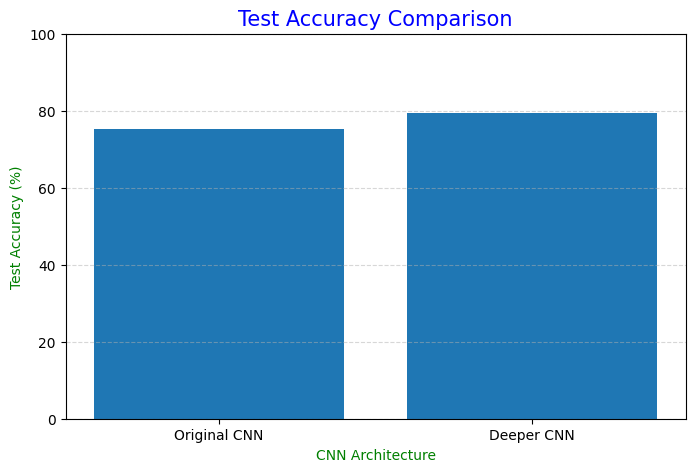

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(comparison_results["Model"], comparison_results["Test Accuracy (%)"])

plt.title("Test Accuracy Comparison", fontsize = 15, color = "blue")
plt.xlabel("CNN Architecture", fontsize = 10, color = "green")
plt.ylabel("Test Accuracy (%)", fontsize = 10, color = "green")
plt.ylim(0, 100)
plt.grid(axis = "y", linestyle = "--", alpha = 0.5)

plt.show()

## 22. Save the Deeper CNN Model :

In [24]:
torch.save(deeper_model.state_dict(), "cifar10_deeper_cnn.pth")

## 23. Compare Training Loss of Both Models :

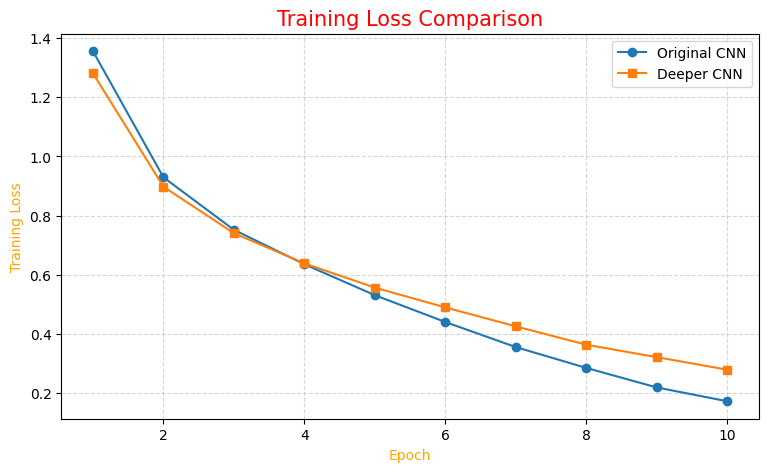

In [25]:
plt.figure(figsize = (9, 5))

plt.plot(range(1, len(train_losses) + 1), train_losses, marker = 'o', label = 'Original CNN')
plt.plot(range(1, len(deeper_train_losses) + 1), deeper_train_losses, marker = 's', label = 'Deeper CNN')

plt.title("Training Loss Comparison", fontsize = 15, color = "red")
plt.xlabel("Epoch", fontsize = 10, color = "orange")
plt.ylabel("Training Loss", fontsize = 10, color = "orange")
plt.legend()
plt.grid(True, linestyle = '--', alpha = 0.5)

plt.show()

## 24. Save the Final Model Comparison : 

In [26]:
comparison_results.to_csv("cifar10_model_comparison.csv", index = False)
display(comparison_results.round(4))

,Model,Test Accuracy (%),Test Loss
0,Original CNN,75.22,1.0405
1,Deeper CNN,79.40,0.7193
